## Chapter 08 - Using Regression to Test for Differences with t-tests

In this chapter we will cover how to use the `ols()` function to perform a t-test, how to use the `ttest_ind()` function to do the same, how to use random data to create a histogram and a *p-value* for a t-test, and how to understand the relationship between the *F-distribution* and the *t-distribution*.

In [12]:
import numpy as np # to generate random numbers
import pandas as pd # for DataFrames
import statsmodels.formula.api as smf # for ols()
from scipy import stats # for ttest_ind()
import seaborn as sns # for the histplot() function

### Using the `ols()` function to do a t-test

If we want to peform a t-test, the first thing we need is some data. In this chapter, we will use the length of time it took people to recover from a cold, grouped into whether the people took a certain drug or not.

In [2]:
## the amount of time required to recover
## using two different drugs
drug_a = [8, 12, 22]
drug_b = [20, 29, 39]

The times in `drug_a` and `drug_b` are the values we want to predict with the `ols()` function. In other words, the dependent variable should contain the times it took everyone to revover. Since we only have a single dependent variable, we can concatenate the times fro drugs A and B together with the `+` operator.

In [3]:
## now, concatenate the times to recover into a single variable
recovery_time = drug_a + drug_b

## print out the values
recovery_time

[8, 12, 22, 20, 29, 39]

Now that we have the times to recover as a single variable, `recovery_time`, we need a way to keep track of which drug corresponds with which time. We'll achieve this be creating a **factor**. A **factor** is essentially a discrete variable that has a limited number of options. Here we will create a factor that tells us that the first 3 values in `recovery_time` should be associcated with drug A, and the remaining values, with drug B.

In [4]:
## create a "factor" variable that allows us to keep track
## of which drug is associated with which time in recovery_time
drug = (['a']*3)+(['b']*3)
drug

['a', 'a', 'a', 'b', 'b', 'b']

Now let's combine `recovery_time` and `drug` in a single `DataFrame` that puts all of our data in one place.

In [5]:

## create a DataFrame
df = pd.DataFrame({
    'time': recovery_time,
    'drug': pd.Categorical(drug)
})
df

,time,drug
0,8,a
1,12,a
2,22,a
3,20,b
4,29,b
5,39,b


Now we have a `DataFrame` that pairs each recovery time with a drug label. Let's use the data to do a regression where we use `drug` to predict the recovery `time`.

In [6]:
model = smf.ols('time ~ drug', data=df)
results = model.fit()
results.summary()

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/statsmodels/regression/linear_model.py:3158: ValueWarning: omni_normtest is not valid with less than 8 observations; 6 samples were given.
  omni, omnipv = cached("omni_normtest", lambda: omni_normtest(self.wresid))


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                   time   R-squared:                       0.553
Model:                            OLS   Adj. R-squared:                  0.442
Method:                 Least Squares   F-statistic:                     4.956
Date:                Mon, 16 Nov 2026   Prob (F-statistic):             0.0900
Time:                        10:32:03   Log-Likelihood:                -20.092
No. Observations:                   6   AIC:                             44.18
Df Residuals:                       4   BIC:                             43.77
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     14.0000      4.871      2.874      0.045       0.477      27.523
drug[T.b]     15.3333      6.888      2.226      0.090      -3.791      34.457
==============================================================================
Omnibus:                          nan   Durbin-Watson:                   2.099
Prob(Omnibus):                    nan   Jarque-Bera (JB):                0.521
Skew:                           0.193   Prob(JB):                        0.771
Kurtosis:                       1.609   Cond. No.                         2.62
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

On the right side of the top table, we see the *p*-value for our *t*-test `Prob (F-statistic): 0.0900`. Thus we fail to reject the null hypothesis that using 2 means per drug to predict recovery time is significantly different from using a singel overall mean.

The other thing worth noting in the output are in the `coef` column where we see the coefficients for the two drugs. 14.0 is the mean recovery time for each person who took drug A, and 15.3 is the offset from the y-axis intercept for each person who took drug B. The offset for drug B is the mean recovery time for each person who took drug B, minus the y-axis intercept. In other words, the mean value for Drug B is the intercept 14.0 plus the coefficient for Drug B 15.3. So the mean recovery time for people that took Drug B is 14 + 15.3 = 29.3.

now that we know how to do a *t*-test using the `ols()` function, let's learn how to do a *t*-test the way most people would do it, using the `ttest_ind()` function.

### Using the `ttest_ind()` function to do a *t*-test

Using the `ttest_ind()` function, where the  `ind` refers to the fact that both samples are independent, which, in this case means that they were not measured from the same people, is really straight forward. You simply pass it the two variables, one for each group of measurement – in this case, the recovery times for `drug_a` and `drug_b`, make sure to set `equal_var=True` to assume that the **Population Variances** are the same for both populations, so that we can compare the *p*-value to what we got when we used the `ols()` function – and recieve the results.

In [8]:
## t-test with equal variances = F-test
stats.ttest_ind(drug_a, drug_b, equal_var=True)

TtestResult(statistic=np.float64(-2.2260960250808055), pvalue=np.float64(0.0900003532186857), df=np.float64(4.0))

As we see, the *p*-value when we use `ttest_ind()` is the same as when we use `ols()`. The big differences are that `ttest_ind()` is a little easier to use since we didn´t have to concatenate the recovery times for both drugs or create a `factor` variable.

Now let's use random data to create a histogram that we can use to calculate a *p*-value for a *t*-test. This will verify the intuition for what the *p*-value represents.

### Using random data to create a histogram and a *p*-value for a *t*-test

Using random data to create a histogram and calcualte a *p*-value for a *t*-test is pretty much the same as we did in Chapters 6 and 7 for Linear Multiple Regresssion.

<Axes: ylabel='Count'>

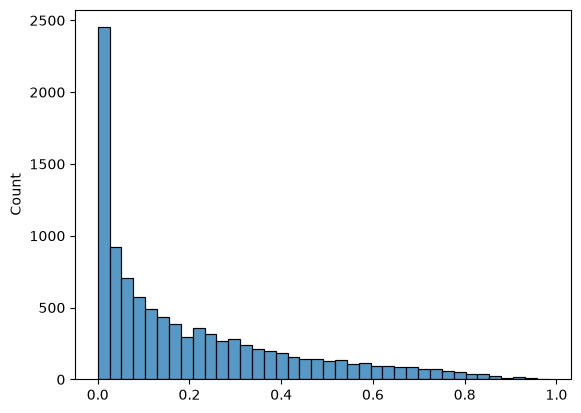

In [13]:
## Since we are going to generate random datasets, we will need to 
## make sure the results are reproduceable
np.random.seed(42)

all_data = drug_a + drug_b

## To generate random datasets, we will use a normal dist. based on our
## observed data, so we will need to calculate the estimated mean and SD from
## that data.
mean_all_data = np.mean(all_data)
sd_all_data = np.std(all_data, ddof=1)

## Next, we define the number of random datasets to create.
num_rand_datasets = 10_000

## and we define the number of data points per dataset
num_datapoints = 3

## Here we create a factor that keeps track of which drug each recovery time 
## is associated with
drugs = ['a'] * num_datapoints + ['b'] * num_datapoints

## then, we create an empty array that is num.rand.datasets long
rand_r_squared = np.empty(num_rand_datasets)

## ...and fill this array with the model results from each of our random datasets
for i in range(num_rand_datasets):

    ## generate random recovery times for each drug
    rand_drug_a_recovery = np.random.normal(mean_all_data, sd_all_data, num_datapoints)
    rand_drug_b_recoery = np.random.normal(mean_all_data, sd_all_data, num_datapoints)

    ## bundle the random values together in a DataFrame
    data = pd.DataFrame({
        'x': pd.Categorical(drugs),
        'y': np.concatenate([rand_drug_a_recovery, rand_drug_b_recoery])
    })

    ## fit regression and calculate R-squared
    model = smf.ols('y ~ x', data=data)
    model_results = model.fit()
    rand_r_squared[i] = model_results.rsquared

## draw a histogram of the $R^2$ values with `histplot()`
sns.histplot(data=rand_r_squared)


...and calculate the *p*-value as the percentage of "random" $R^2$ values, greater than, or equal to, the one we got for our original data.

In [15]:
## The number of randomly generated r-squared >= the original r-squared
num_greater = np.sum(rand_r_squared >= results.rsquared)

p_value = num_greater / num_rand_datasets

p_value

np.float64(0.0928)

In other words, the *p*-value created with the histogram is essentialy the same as the *p*-value created using the `ols()` function.

### Understanding the relationship between the *F*-distribution and the *t*-distribution

Now, let's see how the *F*-distribution is related ot the *t*-distribution. I could tell you that the *F*-distribution is a *generalization* of the *t*-distribution and that you can square any *t*-value and use it as an *F*-value, to get the exact same *p*-value; but it's better to show you. So we will start by doing the *t*-test we did before, only this time we will save the output in a variable called `t_test_stuff`.

In [ ]:
## t-test with equal varainces = F-test
t_test_stuff = stats.ttest_ind(drug_a, drug_b, equal_var=True)
t_test_stuff

TtestResult(statistic=np.float64(-2.2260960250808055), pvalue=np.float64(0.0900003532186857), df=np.float64(4.0))

In [ ]:
## Access the t-value
t_test_stuff.statistic

np.float64(-2.2260960250808055)

Like the *F*-value, the *t*-value is an x-axis coordinate underneath a curve. Now, let's square the *t*-value for the *t*-tests.

In [19]:
t_test_stuff.statistic ** 2

np.float64(4.955503512880562)

...and compare the squared *t*-value to the *F*-value we got when we did the *t*-test with `ols()`.

In [20]:
results.fvalue

np.float64(4.9555035128805605)

Notice that both values are the same. This is true fro any *t*-test. The *t*-value can be squared and used as an *F*-value with an *F*-distribution with DF1=1 (meaning we are comparing a simple model with 1 parameter to a fancy model with 2 parameters), and DF2= n - $p_{Fancy}$. In this example n = 6, both drugs had 3 measurements each, and $p_{Fancy}$ = 2, since we had one mean value per drug, so DF2= 4.

Now, let's show that we can get the same *p*-values both ways. First, we'll calculate the *p*-value from the *F*-distribution using the original *F*-value.

In [22]:
## First, import 'f'
from scipy.stats import f

## P-value with f-distribution
df1 = 1
df2 = 4

1-f.cdf(x=results.fvalue, dfn=df1, dfd=df2)

## then we square the *t*-value and calculate the *p*-value from an *F*-distribution
1-f.cdf(x=(t_test_stuff.statistic ** 2), dfn=df1, dfd=df2)

np.float64(0.09000035321868594)

And we see that both *p*-values are the same, with only a small rounding error in the decimal. So now we have seen that the *F*-distribution is a generalisation of the *t*-distribution and that you can square any *t*-value and use it as an *F*-value to get the exact same *p*-value.